In [1]:
# Set seeds for reproducibility
import random
random.seed(0)

import numpy as np
np.random.seed(0)

import tensorflow as tf
tf.random.set_seed(0)

# Data collection from Kaggel

In [2]:
import os
import json
from zipfile import ZipFile
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models

In [4]:
!pip install kaggle

In [6]:
kaggle_credentails = json.load(open("kaggle.json"))

In [7]:

# setup Kaggle API key as environment variables
os.environ['KAGGLE_USERNAME'] = kaggle_credentails["username"]
os.environ['KAGGLE_KEY'] = kaggle_credentails["key"]

In [8]:
# 4️⃣ Download your dataset
!kaggle datasets download -d rm1000/augmented-apple-disease-detection-dataset

# 5️⃣ Unzip it
!unzip -q augmented-apple-disease-detection-dataset.zip -d apple_disease_data

Dataset URL: https://www.kaggle.com/datasets/rm1000/augmented-apple-disease-detection-dataset
License(s): CC0-1.0
 99% 592M/599M [00:05<00:00, 170MB/s]
100% 599M/599M [00:05<00:00, 118MB/s]


In [9]:
!ls

apple_disease_data			       drive	    sample_data
augmented-apple-disease-detection-dataset.zip  kaggle.json


In [10]:
print(os.listdir("/content/apple_disease_data/train_augmented"))


print(len(os.listdir("/content/apple_disease_data/train_augmented/Apple Scab")))
print(os.listdir("/content/apple_disease_data/train_augmented/Apple Scab")[:5])

print(len(os.listdir("/content/apple_disease_data/train_augmented/Black Rot")))
print(os.listdir("/content/apple_disease_data/train_augmented/Black Rot")[:5])

print(len(os.listdir("/content/apple_disease_data/train_augmented/Cedar Apple Rust")))
print(os.listdir("/content/apple_disease_data/train_augmented/Cedar Apple Rust")[:5])

print(len(os.listdir("/content/apple_disease_data/train_augmented/Healthy")))
print(os.listdir("/content/apple_disease_data/train_augmented/Healthy")[:5])

['Apple Scab', 'Healthy', 'Cedar Apple Rust', 'Black Rot']
3000
['b24daaef-81e1-47fc-a858-b8c8b346d956___FREC_Scab 2927_270deg.JPG', '_651_6197242.png', '84ef6106-d401-44fb-a5c9-be5ef93cb4e7___FREC_Scab 2921.JPG', '_1532_7016450.png', '_1978_9794240.png']
3000
['_1743_1889634.png', '4db50338-6897-4d69-8147-717cae13879c___JR_FrgE.S 8645_270deg.JPG', '3d33710d-c091-4dae-a491-ef813ea2d34b___JR_FrgE.S 2885.JPG', '3e340ca3-47d5-4a22-9f40-e91f3eea2be6___JR_FrgE.S 8747_new30degFlipLR.JPG', 'acb4845c-bee1-478c-b11c-ade0ae397c51___JR_FrgE.S 8818_270deg.JPG']
3000
['a9c36955-73f5-43d5-9e1e-03672ed95b38___FREC_C.Rust 3893_new30degFlipTB.JPG', '_1098_1124563.png', '_259_6554818.png', '_1540_1402742.png', '_672_4103738.png']
3000
['_1992_3960982.png', '_1703_5380449.png', '37581d20-bd40-4aca-81ae-00d83473d578___RS_HL 8091.JPG', '_770_295408.png', '0f33804a-5389-49cc-abb1-c414b243991b___RS_HL 7321.JPG']


In [11]:
# Dataset Path
base_dir = '/content/apple_disease_data/train_augmented'

(256, 256, 3)


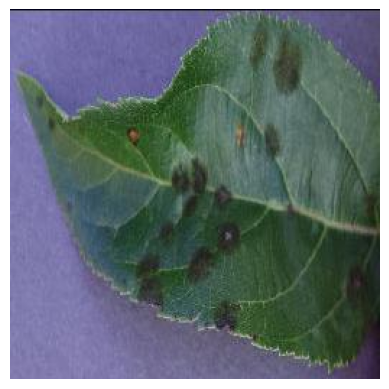

In [12]:
image_path = '/content/apple_disease_data/train_augmented/Apple Scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_90deg.JPG'

# Read the image
img = mpimg.imread(image_path)

print(img.shape)
# Display the image
plt.imshow(img)
plt.axis('off')  # Turn off axis numbers
plt.show()

In [13]:
image_path = '/content/apple_disease_data/train_augmented/Apple Scab/0261a6e4-21f8-481a-8827-b674e6955644___FREC_Scab 3055_270deg.JPG'

# Read the image
img = mpimg.imread(image_path)

print(img)

[[[  4   0   9]
  [156 148 161]
  [162 153 170]
  ...
  [157 149 172]
  [159 151 174]
  [160 152 175]]

 [[  6   0  11]
  [158 150 163]
  [163 154 171]
  ...
  [155 147 170]
  [156 148 171]
  [157 149 172]]

 [[  9   1  14]
  [160 152 165]
  [163 154 171]
  ...
  [153 145 168]
  [154 146 169]
  [153 145 168]]

 ...

 [[ 10   0   9]
  [ 54  38  51]
  [ 91  73  87]
  ...
  [144 136 157]
  [145 137 158]
  [144 136 157]]

 [[  8   0   7]
  [ 45  29  42]
  [ 84  66  80]
  ...
  [145 137 158]
  [144 136 157]
  [141 133 154]]

 [[  8   0   7]
  [ 38  22  35]
  [ 79  61  75]
  ...
  [145 137 158]
  [143 135 156]
  [140 132 153]]]


In [14]:
# Image Parameters
img_size = 224
batch_size = 32

In [15]:
# Image Data Generators
data_gen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2  # Use 20% of data for validation
)

In [16]:
# Train Generator
train_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='training',
    class_mode='categorical'
)

Found 9600 images belonging to 4 classes.


In [17]:
# Validation Generator
validation_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='validation',
    class_mode='categorical'
)

Found 2400 images belonging to 4 classes.


In [18]:
# Model Definition
model = models.Sequential()

model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(img_size, img_size, 3)))
model.add(layers.MaxPooling2D(2, 2))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D(2, 2))


model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(train_generator.num_classes, activation='softmax'))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
# model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    47,776,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,796,420 (182.33 MB)

 Trainable params: 47,796,420 (182.33 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Compile the Model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [21]:
# Training the Model
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,  # Number of steps per epoch
    epochs=5,  # Number of epochs
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // batch_size  # Validation steps
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.6429 - loss: 1.7743

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


300/300 ━━━━━━━━━━━━━━━━━━━━ 39s 108ms/step - accuracy: 0.6434 - loss: 1.7709 - val_accuracy: 0.8529 - val_loss: 0.4073
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - accuracy: 0.9046 - loss: 0.2552 - val_accuracy: 0.9029 - val_loss: 0.2640
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 40s 105ms/step - accuracy: 0.9435 - loss: 0.1497 - val_accuracy: 0.9467 - val_loss: 0.1656
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 31s 105ms/step - accuracy: 0.9695 - loss: 0.0788 - val_accuracy: 0.9596 - val_loss: 0.1205
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - accuracy: 0.9832 - loss: 0.0429 - val_accuracy: 0.9079 - val_loss: 0.3248


In [22]:
# Model Evaluation
print("Evaluating model...")
val_loss, val_accuracy = model.evaluate(validation_generator, steps=validation_generator.samples // batch_size)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Evaluating model...
75/75 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.9026 - loss: 0.3503
Validation Accuracy: 90.79%


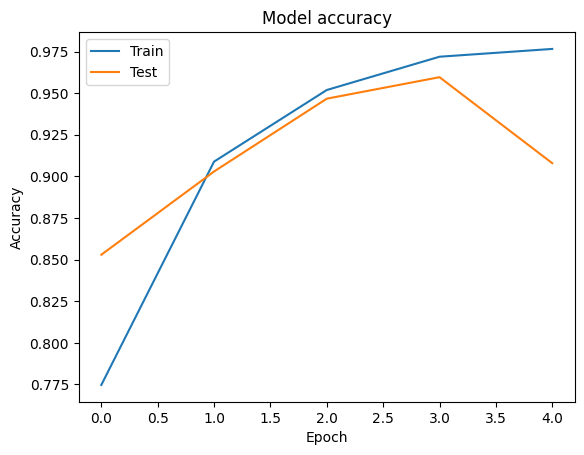

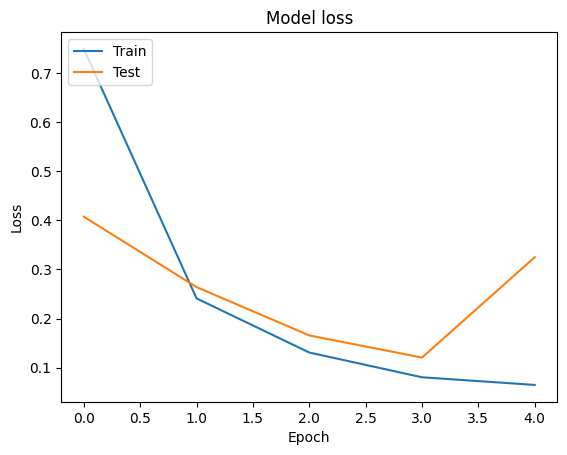

In [23]:
# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

In [24]:

# Function to Load and Preprocess the Image using Pillow
def load_and_preprocess_image(image_path, target_size=(224, 224)):
    # Load the image
    img = Image.open(image_path)
    # Resize the image
    img = img.resize(target_size)
    # Convert the image to a numpy array
    img_array = np.array(img)
    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)
    # Scale the image values to [0, 1]
    img_array = img_array.astype('float32') / 255.
    return img_array

# Function to Predict the Class of an Image
def predict_image_class(model, image_path, class_indices):
    preprocessed_img = load_and_preprocess_image(image_path)
    predictions = model.predict(preprocessed_img)
    predicted_class_index = np.argmax(predictions, axis=1)[0]
    predicted_class_name = class_indices[predicted_class_index]
    return predicted_class_name


In [25]:
# Create a mapping from class indices to class names
class_indices = {v: k for k, v in train_generator.class_indices.items()}

In [26]:
class_indices

{0: 'Apple Scab', 1: 'Black Rot', 2: 'Cedar Apple Rust', 3: 'Healthy'}

In [27]:
# saving the class names as json file
json.dump(class_indices, open('class_indices.json', 'w'))

In [32]:
# Example Usage
image_path = '/content/apple_disease_data/train_augmented/Apple Scab/023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Scab 3487_270deg.JPG'
predicted_class_name = predict_image_class(model, image_path, class_indices)

# Output the result
print("Predicted Class Name:", predicted_class_name)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Predicted Class Name: Apple Scab


In [33]:
# Save the model
model.save("apple_disease_model.h5")


In [34]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
import os


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


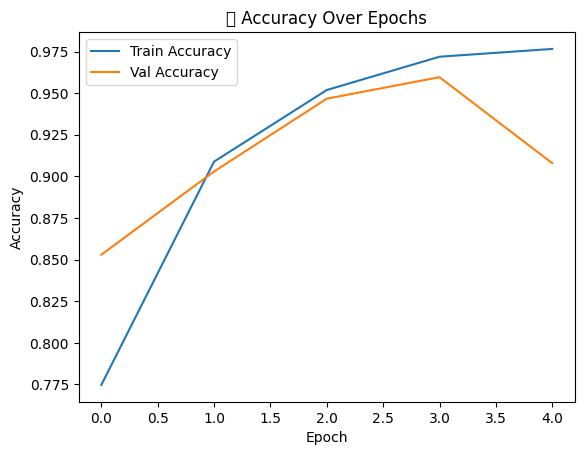

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


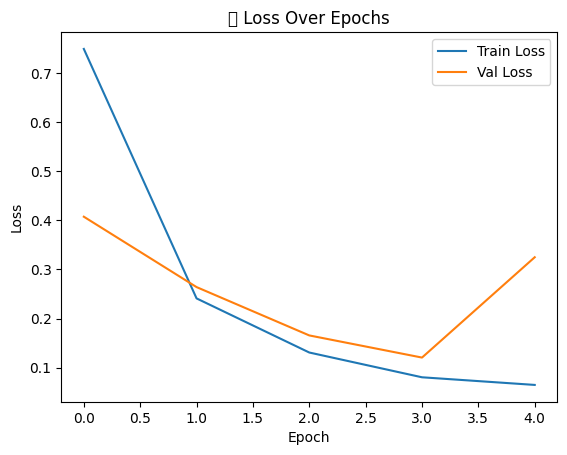

In [35]:
# Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('📈 Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('📉 Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [36]:
# Get true labels and predictions
y_true = []
y_pred = []

for images, labels in val_dataset:
    preds = model.predict(images)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

# Classification report
print("📄 Classification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(xticks_rotation=90, cmap='Blues')
plt.title('🧩 Confusion Matrix')
plt.show()


NameError: name 'val_dataset' is not defined